# MovieLens 100K Data Exploration and Preprocessing

**Contributor:** Manish Rao Joginipalli  
**Group:** 5  
**Course:** PhDAI-732-B01 Fundamentals of AI-Enabled Systems

This contribution covers the dataset inspection, cleaning audit, data types,
rating and activity summaries, sparsity, and exploratory plots for Deliverable 1.
It can be incorporated into the group's shared notebook alongside the model work.

**Colab:** Upload this file to a fresh CPU runtime and choose **Runtime → Run all**.
Only pandas, NumPy, and matplotlib are needed; these are included in Colab.
The notebook downloads the official MovieLens 100K archive automatically.

**Execution note:** The saved checks were executed locally in Python. Run this
notebook in Colab and save its outputs before placing it in the shared OneDrive
folder. The report section reflects these verified data checks and summaries.


## 1 Import libraries

In [1]:
import hashlib
import io
import json
import platform
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print('Python:', platform.python_version())
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)


Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3


## 2 Load the official MovieLens 100K data

In [2]:
dataset_url = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
cache = Path('movielens_data')
cache.mkdir(exist_ok=True)
archive_path = cache / 'ml-100k.zip'
if not archive_path.exists():
    with urlopen(dataset_url, timeout=60) as response:
        archive_path.write_bytes(response.read())
archive_bytes = archive_path.read_bytes()
archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()

with ZipFile(io.BytesIO(archive_bytes)) as archive:
    with archive.open('ml-100k/u.data') as file:
        raw = pd.read_csv(
            file, sep='\t',
            names=['user_id', 'item_id', 'rating', 'timestamp']
        )
    with archive.open('ml-100k/u.item') as file:
        movies = pd.read_csv(
            file, sep='|', encoding='latin-1', header=None,
            usecols=[0, 1], names=['item_id', 'title']
        )

print('Raw shape:', raw.shape)
print(raw.head().to_string(index=False))
print('Archive SHA256:', archive_sha256)
print('Dataset source:', dataset_url)

Raw shape: (100000, 4)
 user_id  item_id  rating  timestamp
     196      242       3  881250949
     186      302       3  891717742
      22      377       1  878887116
     244       51       2  880606923
     166      346       1  886397596
Archive SHA256: 50d2a982c66986937beb9ffb3aa76efe955bf3d5c6b761f4e3a7cd717c6a3229
Dataset source: https://files.grouplens.org/datasets/movielens/ml-100k.zip


## 3 Explore and clean the ratings

Check missing fields, exact duplicate rows, repeated user-item pairs, data types,
ID validity, and the allowed rating scale. Records with missing or invalid
required fields would be removed. Repeated user-item pairs would be retained
only once. The observed checks below show whether any removal was necessary.
An unrated user-item pair is an unknown preference, not a zero-star rating, and
is not filled with zero.

In [3]:
data = raw.copy()
for column in ['user_id', 'item_id', 'rating', 'timestamp']:
    data[column] = pd.to_numeric(data[column], errors='coerce')

audit = {
    'raw_rows': int(len(raw)),
    'missing_required_rows': int(data.isna().any(axis=1).sum()),
    'exact_duplicate_rows': int(data.duplicated().sum()),
    'repeated_user_item_pairs': int(data.duplicated(['user_id', 'item_id']).sum())
}
data = data.dropna().drop_duplicates()
valid = (
    data['user_id'].gt(0) & data['item_id'].gt(0) &
    data['user_id'].mod(1).eq(0) & data['item_id'].mod(1).eq(0) &
    data['rating'].between(1, 5) & data['rating'].mod(1).eq(0) &
    data['timestamp'].ge(0) & data['timestamp'].mod(1).eq(0)
)
audit['invalid_rows'] = int((~valid).sum())
data = data.loc[valid].drop_duplicates(['user_id', 'item_id']).copy()
data = data.astype({
    'user_id': 'int64', 'item_id': 'int64',
    'rating': 'float64', 'timestamp': 'int64'
})
audit['clean_rows'] = int(len(data))
audit['removed_rows'] = audit['raw_rows'] - audit['clean_rows']
audit['unknown_movie_ids'] = int((~data['item_id'].isin(movies['item_id'])).sum())

print(pd.Series(audit).to_string())
print('\nFinal data types:')
print(data.dtypes.to_string())
assert not data.isna().any().any()
assert not data.duplicated(['user_id', 'item_id']).any()
assert data['rating'].between(1, 5).all()
assert audit['unknown_movie_ids'] == 0

raw_rows                    100000
missing_required_rows            0
exact_duplicate_rows             0
repeated_user_item_pairs         0
invalid_rows                     0
clean_rows                  100000
removed_rows                     0
unknown_movie_ids                0

Final data types:
user_id        int64
item_id        int64
rating       float64
timestamp      int64


In [4]:
ratings_per_user = data.groupby('user_id').size()
ratings_per_item = data.groupby('item_id').size()
rating_counts = data['rating'].value_counts().sort_index()
n_users = int(data['user_id'].nunique())
n_items = int(data['item_id'].nunique())
density = len(data) / (n_users * n_items)
summary = {
    'ratings': int(len(data)), 'users': n_users, 'movies': n_items,
    'mean_rating': float(data['rating'].mean()),
    'median_rating': float(data['rating'].median()),
    'rating_counts': {str(int(k)): int(v) for k, v in rating_counts.items()},
    'user_rating_min': int(ratings_per_user.min()),
    'user_rating_median': float(ratings_per_user.median()),
    'user_rating_max': int(ratings_per_user.max()),
    'movie_rating_min': int(ratings_per_item.min()),
    'movie_rating_median': float(ratings_per_item.median()),
    'movie_rating_max': int(ratings_per_item.max()),
    'density': float(density), 'sparsity': float(1 - density)
}
print(json.dumps(summary, indent=2))
popular = (
    ratings_per_item.rename('ratings').reset_index()
    .merge(movies, on='item_id')
    .sort_values('ratings', ascending=False).head(5)
)
print('\nMost-rated movies:')
print(popular[['title', 'ratings']].to_string(index=False))

{
  "ratings": 100000,
  "users": 943,
  "movies": 1682,
  "mean_rating": 3.52986,
  "median_rating": 4.0,
  "rating_counts": {
    "1": 6110,
    "2": 11370,
    "3": 27145,
    "4": 34174,
    "5": 21201
  },
  "user_rating_min": 20,
  "user_rating_median": 65.0,
  "user_rating_max": 737,
  "movie_rating_min": 1,
  "movie_rating_median": 27.0,
  "movie_rating_max": 583,
  "density": 0.06304669364224531,
  "sparsity": 0.9369533063577546
}

Most-rated movies:
                    title  ratings
         Star Wars (1977)      583
           Contact (1997)      509
             Fargo (1996)      508
Return of the Jedi (1983)      507
         Liar Liar (1997)      485


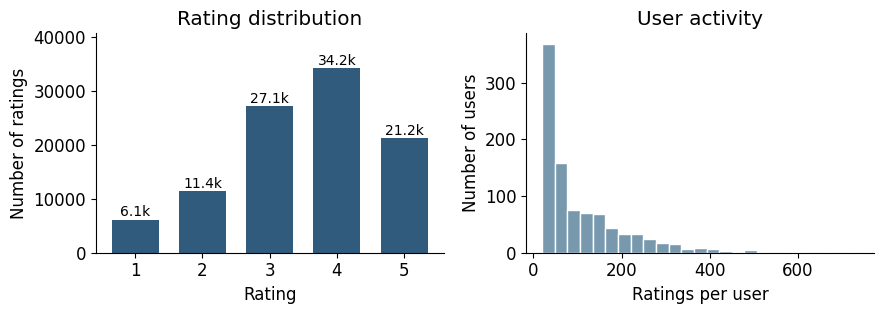

In [5]:
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False,
                     'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].bar(rating_counts.index.astype(int), rating_counts.values,
            color='#315b7d', width=0.7)
axes[0].set(xlabel='Rating', ylabel='Number of ratings',
            title='Rating distribution', xticks=[1, 2, 3, 4, 5])
axes[0].set_ylim(0, rating_counts.max() * 1.19)
for rating, count in rating_counts.items():
    axes[0].text(rating, count + 700, f'{count / 1000:.1f}k',
                 ha='center', fontsize=10)
axes[1].hist(ratings_per_user, bins=25, color='#7798ad',
             edgecolor='white')
axes[1].set(xlabel='Ratings per user', ylabel='Number of users',
            title='User activity')
fig.tight_layout()
fig.savefig('movielens_eda.png', dpi=200, bbox_inches='tight')
plt.show()

## 4 Findings and handoff

The data-quality audit shows whether any observed rating records require removal.
Unrated user-movie pairs remain unknown; they are not imputed as zero-star ratings.
The activity distributions help identify popularity and participation imbalance.
Demographic fairness is not established by these checks.

After execution, the cleaned pandas dataframe is **data**. The input columns for
the team's Surprise model are `data[['user_id', 'item_id', 'rating']]`.
The timestamp is retained for traceability but is not a predictor in the initial
collaborative filtering model. Preserve the team's agreed 75/25 split and seed 42
when integrating these cells with the modeling notebook.

## Reference

Harper, F. M., & Konstan, J. A. (2015). The MovieLens datasets: History and context.
*ACM Transactions on Interactive Intelligent Systems, 5*(4), Article 19.
https://doi.org/10.1145/2827872
